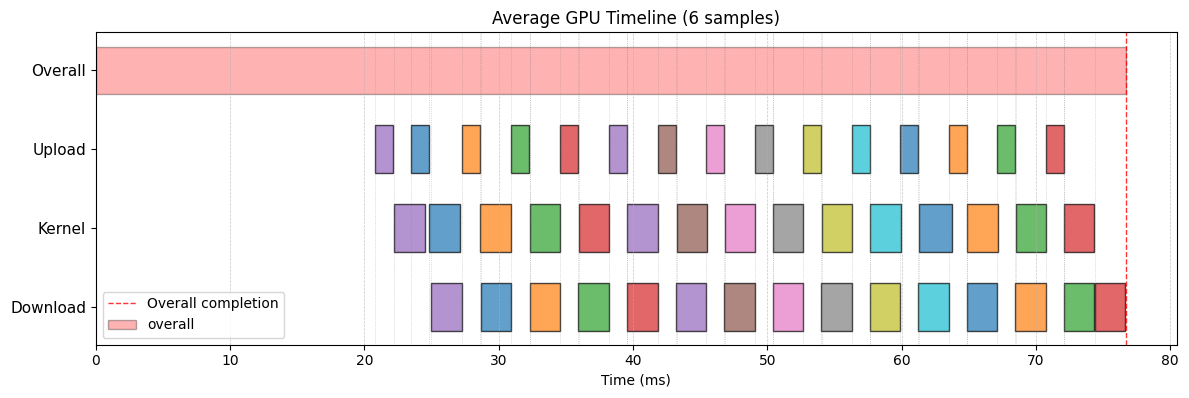


Summary:
Overall average time: 76.68 ms
Download average duration: 2.27 ms
Kernel average duration: 2.27 ms
Upload average duration: 1.34 ms


In [21]:
from __future__ import annotations
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple
import warnings

data_path = "../data/out/parsed_data.txt"
with open(data_path, "r") as f:
    data = f.read()
data = eval(data)

# Data appears to already be in milliseconds based on sample values
_TIME_UNIT_FACTOR = 1  # Renamed for clarity


def _stack_to_array(seqs: List[List[int]]) -> Tuple[np.ndarray, int]:
    """
    Safely stack nested lists with possibly unequal batch lengths.
    """
    # Handle empty sequence case
    if not seqs:
        return np.array([]), 0

    lengths = [len(s) for s in seqs]
    
    # Handle case where all sequences are empty
    if not lengths or all(l == 0 for l in lengths):
        return np.array([]), 0
    
    nb = max(lengths)
    if len(set(lengths)) != 1:
        warnings.warn("Unequal batch counts across samples; padding with NaN.")
    arr = np.full((len(seqs), nb), np.nan, dtype=float)
    for i, s in enumerate(seqs):
        if len(s) > 0:  # Only assign if sequence is not empty
            arr[i, : len(s)] = s
    return arr, nb


def _mean_per_batch(seqs: List[List[int]]) -> np.ndarray:
    arr, nb = _stack_to_array(seqs)
    if nb == 0:  # Handle empty case
        return np.array([])
    return np.nanmean(arr, axis=0)


def _mean_and_shift_starts(start_seqs: List[List[int]]) -> np.ndarray:
    """
    Shift each sample so its first batch starts at 0, *then* average.
    """
    arr, nb = _stack_to_array(start_seqs)
    if nb == 0:  # Handle empty case
        return np.array([])
    # subtract the first non-nan start in each sample
    offsets = np.nanmin(arr, axis=1, keepdims=True)
    shifted = arr - offsets
    return np.nanmean(shifted, axis=0)


def plot_gpu_timeline(data: Dict[str, List]) -> None:
    # ------------------------------------------------------------------
    # Identify keys programmatically so the script is robust to renames
    # ------------------------------------------------------------------
    overall_ms = np.mean(data["overall_time"]) * _TIME_UNIT_FACTOR

    # Per batch durations and starts
    durations_ms = {}
    starts_ms = {}
    
    # More robust key mapping
    key_mappings = {
        "Upload_time": "Start_upload",
        "Kernel_time": "Start_kernel", 
        "Download_time": "Start_download"
    }
    
    stage_keys = [k for k in data if k.endswith("_time") and "overall" not in k]
    
    for sk in stage_keys:
        # Skip empty data keys
        if not data[sk]:
            print(f"Skipping {sk} - no data available")
            continue
            
        stage = sk[:-5].lower()  # strip "_time"
        
        durations_ms[stage] = _mean_per_batch(data[sk]) * _TIME_UNIT_FACTOR
        
        # Skip if durations are empty (no valid data)
        if len(durations_ms[stage]) == 0:
            print(f"Skipping {stage} - no valid duration data")
            if stage in durations_ms: # Ensure key exists before deleting
                 del durations_ms[stage]
            continue
        
        # Use explicit mapping instead of string manipulation
        if sk in key_mappings:
            start_arr_key = key_mappings[sk]
        else:
            # Fallback for unknown keys
            start_arr_key = f"Start_{stage}"
            
        if start_arr_key in data and data[start_arr_key]:
            # Fix: pass the list directly, not converted to numpy array
            starts_ms[stage] = _mean_per_batch(data[start_arr_key]) * _TIME_UNIT_FACTOR
        else:
            print(f"Warning: Start times not found for {stage} (looking for {start_arr_key})")
            starts_ms[stage] = np.zeros_like(durations_ms[stage])

    # ------------------------------------------------------------------
    # Plot -------------------------------------------------------------
    # ------------------------------------------------------------------
    stages_plot_order = ["download", "kernel", "upload", "overall"]
    # Filter out missing stages gracefully
    stages_plot_order = [s for s in stages_plot_order if s in durations_ms or s == "overall"]

    fig, ax = plt.subplots(figsize=(12, (1 + 0.6 * len(stages_plot_order))*1.2))
    barh_kwargs_default = dict(height=0.6, align="center", alpha=0.7, edgecolor="black")

    yticks = []
    yticklabels = []
    y_base = 0
    max_time = overall_ms  # Track maximum time for proper vline height

    for stage in stages_plot_order:
        if stage == "overall":
            overall_bar_kwargs = barh_kwargs_default.copy()
            overall_bar_kwargs["color"] = "red"
            overall_bar_kwargs["alpha"] = 0.3
            ax.barh(y=y_base, width=overall_ms, left=0, **overall_bar_kwargs, 
                   label="overall")
        else:
            # Plot each batch as a separate bar with different colors
            for i, (left, width) in enumerate(zip(starts_ms[stage], durations_ms[stage])):
                color = f"C{i % 10}"  # Cycle through colors if more than 10 batches
                ax.barh(y=y_base, width=width, left=left, **barh_kwargs_default, color=color)
            
            # Update max_time for proper vline scaling
            if stage in starts_ms and stage in durations_ms and len(starts_ms[stage]) > 0 and len(durations_ms[stage]) > 0 :
                stage_max_val = starts_ms[stage] + durations_ms[stage]
                if len(stage_max_val) > 0:
                    stage_max = np.nanmax(stage_max_val)
                    max_time = max(max_time, stage_max)
                    
        yticks.append(y_base)
        yticklabels.append(stage.capitalize())
        y_base += 1

    # Add vertical lines at key time points with proper height
    ax.axvline(overall_ms, color="red", linestyle="--", linewidth=1, 
               alpha=0.8, label="Overall completion")
    
    # Add vertical grid lines for start times
    for stage_name in [s for s in stages_plot_order if s != "overall"]: # Renamed stage to stage_name to avoid conflict
        if stage_name in starts_ms:
            for start_val in starts_ms[stage_name]: # Renamed start to start_val
                if not np.isnan(start_val):
                    ax.axvline(start_val, color="gray", linestyle=":", linewidth=0.5, alpha=0.5)

    ax.set_yticks(yticks)
    ax.set_yticklabels(yticklabels, fontsize=11)
    ax.set_xlabel("Time (ms)")
    ax.set_title(f"Average GPU Timeline ({len(data['overall_time'])} samples)")
    ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.7)
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print(f"\nSummary:")
    print(f"Overall average time: {overall_ms:.2f} ms")
    for stage_name in [s for s in stages_plot_order if s != "overall"]: # Renamed stage to stage_name
        if stage_name in durations_ms and len(durations_ms[stage_name]) > 0:
            avg_duration = np.nanmean(durations_ms[stage_name])
            print(f"{stage_name.capitalize()} average duration: {avg_duration:.2f} ms")

plot_gpu_timeline(data)

In [22]:
np.mean(data['cpu_overall_time'])/np.mean(data['overall_time'])

d:\User\Software\MiniConda3\envs\SuperCondaEnv\Lib\site-packages\numpy\core\fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
d:\User\Software\MiniConda3\envs\SuperCondaEnv\Lib\site-packages\numpy\core\_methods.py:192: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


nan